# Before we start - important!

You can modify this notebook directly and work on the exercices but don't forget to save a copy in your Goodle Drive (in the _File_ tab select "save a copy in Drive")!

You can use the menu on the left to navigate the notebook, add new line of code or text in "+ Code" or "+ Text" above.

# Read images

We will mount this workshop dataset from GitHub to access the images (we are actually cloning it here, into Google colab environment).

You can also for example mount your dataset from your google drive if you are using your own images.

In [1]:
import os

git_folder = "CatarinaNSSilva/MARE_workshop_Machine_Learning"
if os.path.exists(git_folder) == False:
   !git clone https://github.com/CatarinaNSSilva/MARE_workshop_Machine_Learning.git

path_to_images = git_folder

Cloning into 'MARE_workshop_Machine_Learning'...
remote: Enumerating objects: 527, done.
remote: Counting objects: 100% (238/238), done.
remote: Compressing objects: 100% (203/203), done.
remote: Total 527 (delta 49), reused 195 (delta 32), pack-reused 289 (from 1)
Receiving objects: 100% (527/527), 438.19 MiB | 34.79 MiB/s, done.
Resolving deltas: 100% (68/68), done.
Updating files: 100% (156/156), done.


In [2]:
path_to_images

'CatarinaNSSilva/MARE_workshop_Machine_Learning'

# Image classification

This practice uses the [TensorFlow library](https://www.tensorflow.org/resources/libraries-extensions). TensorFlow  is a platform for machine learning. The library has a large number of integrated functions.

To run this example, we first need to install and import several required packages within the library, including [Keras](https://keras.io/about/#:~:text=Keras%20is%20the%20high%2Dlevel,solutions%20with%20high%20iteration%20velocity.), a high-level API of the TensorFlow platform, an approachable, highly-productive interface for solving machine learning problems, with a focus on modern deep learning.

We will also import other libraries that we will need such as [Numpy](https://numpy.org/) and [Matplotlib](https://matplotlib.org/) for visualization.

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import PIL
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

## Create a dataset

In [4]:
batch_size = 32
img_height = 180
img_width = 180

It's good practice to use a validation split when developing your model. Use ~80% of the images for training and 20% for validation.

In [5]:
data_dir = '/content/MARE_workshop_Machine_Learning/images'

In [6]:
train_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="training",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 135 files belonging to 3 classes.
Using 108 files for training.


In [7]:
val_ds = tf.keras.utils.image_dataset_from_directory(
  data_dir,
  validation_split=0.2,
  subset="validation",
  seed=123,
  image_size=(img_height, img_width),
  batch_size=batch_size)

Found 135 files belonging to 3 classes.
Using 27 files for validation.


In [8]:
class_names = train_ds.class_names
print(class_names)

['perch', 'pumpkinseed', 'striped_bass']


In [9]:
data_dir_test = '/content/MARE_workshop_Machine_Learning/images_test'

In [10]:
test_dataset = tf.keras.utils.image_dataset_from_directory(
    data_dir_test,
    shuffle=False,
    batch_size=batch_size,
    image_size=(img_height, img_width))

Found 20 files belonging to 3 classes.


In [11]:
class_names = test_dataset.class_names
print(class_names)

['perch', 'pumpkinseed', 'striped_bass']


## Visualize the data

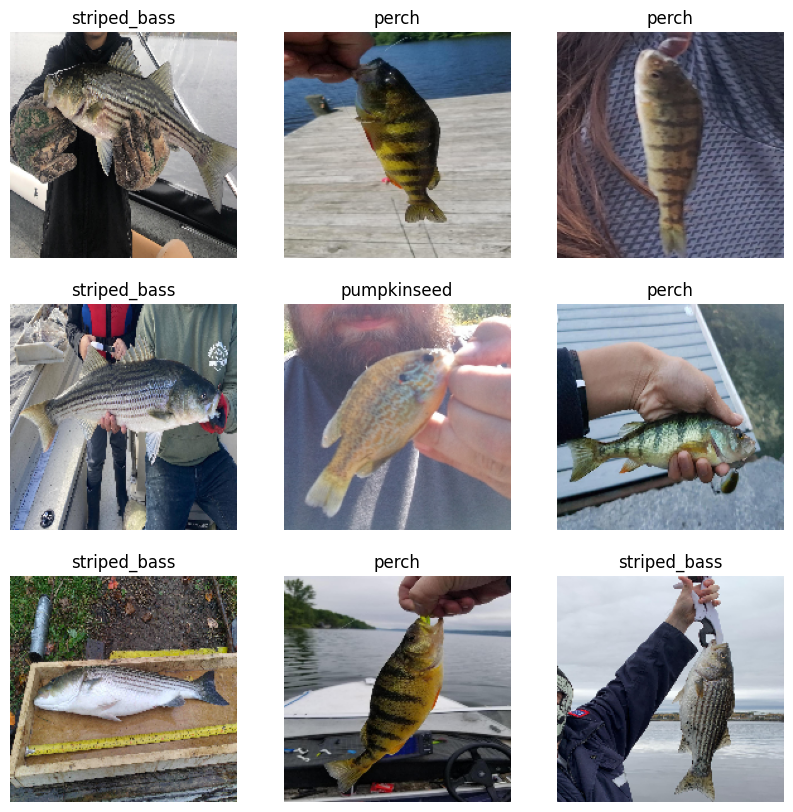

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")

You will pass these datasets to the Keras Model.fit method for training later in this tutorial. If you like, you can also manually iterate over the dataset and retrieve batches of images:

In [13]:
for image_batch, labels_batch in train_ds:
  print(image_batch.shape)
  print(labels_batch.shape)
  break

(32, 180, 180, 3)
(32,)


The image_batch is a tensor of the shape (32, 180, 180, 3). This is a batch of 32 images of shape 180x180x3 (the last dimension refers to color channels RGB). The label_batch is a tensor of the shape (32,), these are corresponding labels to the 32 images.

You can call .numpy() on the image_batch and labels_batch tensors to convert them to a numpy.ndarray.

## Standardize the data

The RGB channel values are in the [0, 255] range. This is not ideal for a neural network; in general you should seek to make your input values small.

Here, you will standardize values to be in the [0, 1] range by using tf.keras.layers.Rescaling:

In [14]:
normalization_layer = layers.Rescaling(1./255)

There are two ways to use this layer. You can apply it to the dataset by calling Dataset.map:

In [15]:
normalized_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
image_batch, labels_batch = next(iter(normalized_ds))
first_image = image_batch[0]
# Notice the pixel values are now in `[0,1]`.
print(np.min(first_image), np.max(first_image))

0.055831306 1.0


In [16]:
normalized_test_ds = test_dataset.map(lambda x, y: (normalization_layer(x), y))
image_batch, labels_batch = next(iter(normalized_test_ds))
first_image = image_batch[0]
# Notice the pixel values are now in `[0,1]`.
print(np.min(first_image), np.max(first_image))

0.008045411 1.0


Or, you can include the layer inside your model definition, which can simplify deployment. Use the second approach here.

Note: You previously resized images using the image_size argument of tf.keras.utils.image_dataset_from_directory. If you want to include the resizing logic in your model as well, you can use the tf.keras.layers.Resizing layer.

# A basic Keras model

Create the model
The Keras Sequential model consists of three convolution blocks (tf.keras.layers.Conv2D) with a max pooling layer (tf.keras.layers.MaxPooling2D) in each of them. There's a fully-connected layer (tf.keras.layers.Dense) with 128 units on top of it that is activated by a ReLU activation function ('relu'). This model has not been tuned for high accuracy; the goal of this tutorial is to show a standard approach.

In [17]:
num_classes = len(class_names)

model = Sequential([
  layers.Rescaling(1./255, input_shape=(img_height, img_width, 3)),
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes)
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


## Compile the model

For this tutorial, choose the tf.keras.optimizers.Adam optimizer and tf.keras.losses.SparseCategoricalCrossentropy loss function. To view training and validation accuracy for each training epoch, pass the metrics argument to Model.compile.

More about optimizers - [here](https://keras.io/api/optimizers/).

In [18]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

## Model summary

View all the layers of the network using the Keras Model.summary method:

In [19]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,989,027 (15.22 MB)

 Trainable params: 3,989,027 (15.22 MB)

 Non-trainable params: 0 (0.00 B)

## Train the model

Train the model for 10 epochs with the Keras Model.fit method:

In [20]:
epochs=10
history = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=epochs
)

Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 14s 2s/step - accuracy: 0.3981 - loss: 1.9398 - val_accuracy: 0.2593 - val_loss: 1.3129
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.4444 - loss: 1.0772 - val_accuracy: 0.2593 - val_loss: 1.1000
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.5278 - loss: 1.0625 - val_accuracy: 0.2593 - val_loss: 1.2253
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.4537 - loss: 1.0301 - val_accuracy: 0.3333 - val_loss: 1.0461
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.6296 - loss: 0.8939 - val_accuracy: 0.5185 - val_loss: 0.9481
Epoch 6/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.6944 - loss: 0.7533 - val_accuracy: 0.4074 - val_loss: 1.0043
Epoch 7/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.6389 - loss: 0.6867 - val_accuracy: 0.5926 - val_loss: 0.9625
Epoch 8/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 1s/step - accuracy: 0.8796 - loss: 0.5593 - val_accuracy: 0.5926 - val_loss: 0.7146
Epoch 9/10
4/

In [21]:
loss, accuracy = model.evaluate(train_ds)

4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 698ms/step - accuracy: 0.8426 - loss: 0.3451


In [22]:
loss, accuracy = model.evaluate(val_ds)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.6667 - loss: 0.6200


## Visualize training results

Create plots of the loss and accuracy on the training and validation sets:

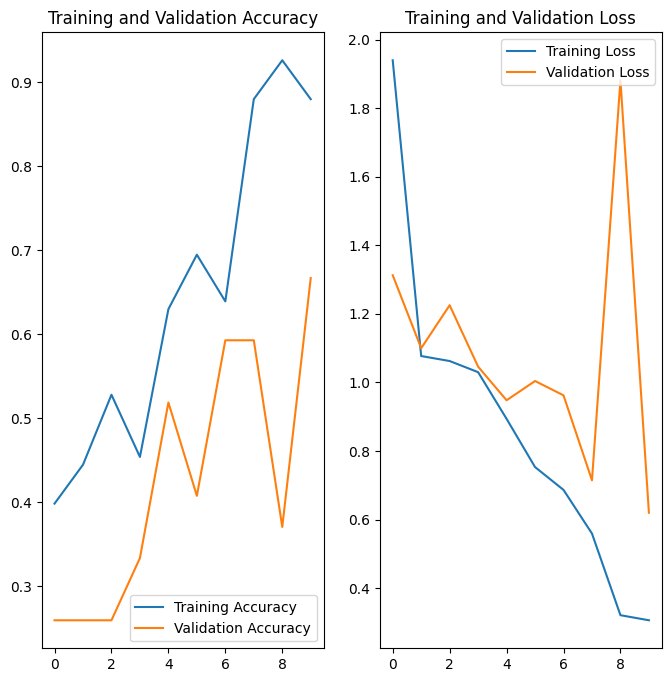

In [23]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

HOMEWORK - Try to increase the overall performance of the model by changing the hyperparameters, data augmentation,...! :)

## Confusion matrix

In [24]:
predictions = model.predict(test_dataset)
predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


array([[-0.16612522, -0.11494483, -2.3889563 ],
       [-1.3399823 , -0.4442953 , -0.8234802 ],
       [-0.3168467 , -0.8425913 , -1.4772677 ],
       [-1.4208117 , -1.9454354 ,  0.3687945 ],
       [ 2.5434062 , -4.765631  ,  0.31331217],
       [ 0.09974156, -0.79980433, -1.036879  ],
       [-2.114232  , -1.6052068 ,  0.08846154],
       [ 0.04647936, -0.95761365, -2.227741  ],
       [-2.231314  , -5.3873305 ,  3.4044385 ],
       [-1.6427689 , -3.0387342 ,  0.09356644],
       [-1.6385756 ,  0.90921444, -2.3765156 ],
       [-1.1471804 ,  0.4328363 , -1.6398057 ],
       [-0.8031985 , -1.3549721 , -0.31141627],
       [-1.4499571 ,  0.29173052, -1.9383543 ],
       [-1.9990431 ,  1.4332272 , -3.1625547 ],
       [-4.267865  , -4.4718976 ,  4.8529887 ],
       [-5.1135917 , -5.450668  ,  6.470353  ],
       [-1.2030073 ,  0.56038564, -2.5737867 ],
       [-1.9062442 , -1.8865288 ,  0.7204841 ],
       [-3.9419692 , -2.3827093 ,  2.8246617 ]], dtype=float32)

In [25]:
for images, labels in test_dataset.take(1):  # only take first element of dataset
    numpy_images = images.numpy()
    numpy_labels = labels.numpy()

In [26]:
numpy_labels

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2],
      dtype=int32)

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_prediction = model.predict(test_dataset)
y_prediction = np.argmax(y_prediction, axis = 1)
y_prediction


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 458ms/step


array([1, 1, 0, 2, 0, 0, 2, 0, 2, 2, 1, 1, 2, 1, 1, 2, 2, 1, 2, 2])

In [28]:
#Create confusion matrix and normalizes it over predicted (columns) or true values, {‘true’, ‘pred’, ‘all’}
result = confusion_matrix(numpy_labels, y_prediction , normalize='true')
print(result)

[[0.4 0.2 0.4]
 [0.  0.8 0.2]
 [0.  0.2 0.8]]


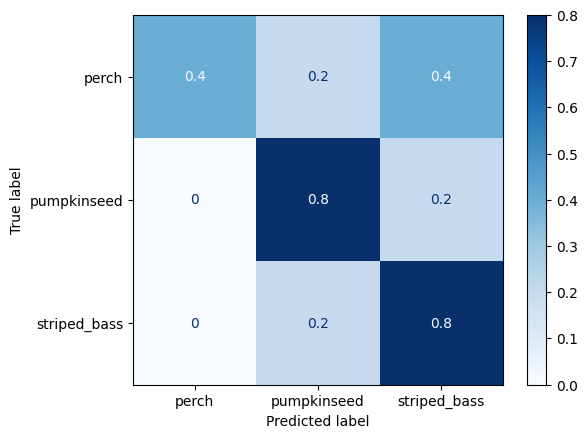

In [29]:
disp = ConfusionMatrixDisplay(confusion_matrix=result,
                              display_labels=class_names)
disp.plot(cmap='Blues')
plt.grid(False)

plt.show()

# Data augmentation

Overfitting generally occurs when there are a small number of training examples. Data augmentation takes the approach of generating additional training data from your existing examples by augmenting them using random transformations that yield believable-looking images. This helps expose the model to more aspects of the data and generalize better.

You will implement data augmentation using the following Keras preprocessing layers: tf.keras.layers.RandomFlip, tf.keras.layers.RandomRotation, and tf.keras.layers.RandomZoom. These can be included inside your model like other layers, and run on the GPU.

Try other transformations, for example, [rotations](https://www.tensorflow.org/api_docs/python/tf/keras/layers/RandomRotation) or [zoom](https://www.tensorflow.org/api_docs/python/tf/keras/layers/RandomZoom).

In [30]:
data_augmentation = keras.Sequential(
  [
    layers.RandomFlip("horizontal",
                      input_shape=(img_height,
                                  img_width,
                                  3)),
        layers.RandomFlip("vertical",
                      input_shape=(img_height,
                                  img_width,
                                  3)),

  ]
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Visualize a few augmented examples by applying data augmentation to the same image several times:

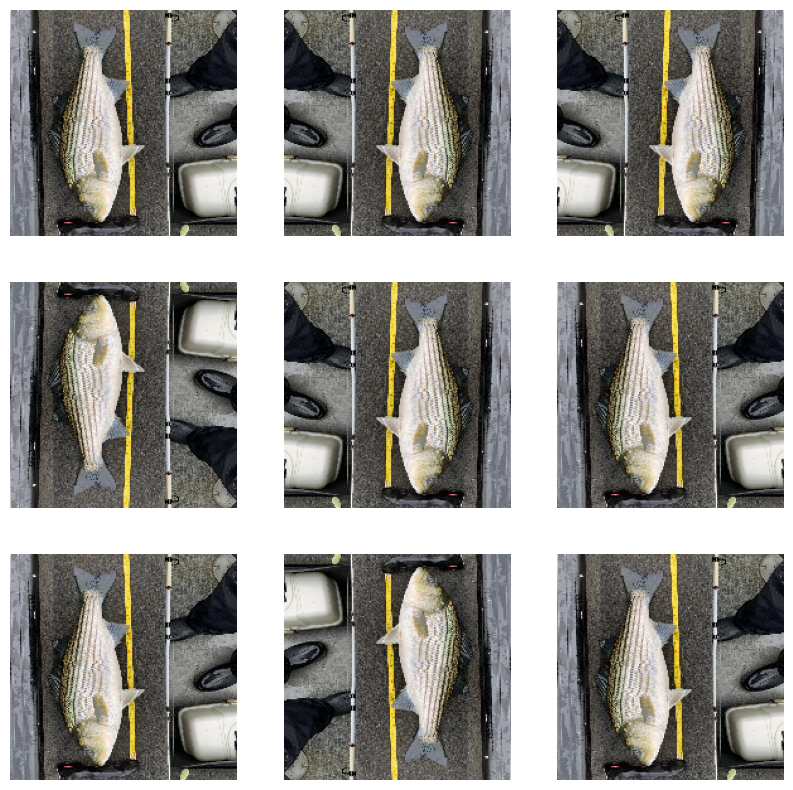

In [31]:
plt.figure(figsize=(10, 10))
for images, _ in train_ds.take(1):
  for i in range(9):
    augmented_images = data_augmentation(images)
    ax = plt.subplot(3,3, i + 1)
    plt.imshow(augmented_images[0].numpy().astype("uint8"))
    plt.axis("off")

## Compile and train model with augmented dataset

You will add data augmentation to your model before training in the next step.

In [32]:
num_classes = len(class_names)

model = Sequential([
  data_augmentation,
  layers.Rescaling(1./255, input_shape=(img_height, img_width, 3)),
  layers.Conv2D(16, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(32, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Conv2D(64, 3, padding='same', activation='relu'),
  layers.MaxPooling2D(),
  layers.Flatten(),
  layers.Dense(128, activation='relu'),
  layers.Dense(num_classes)
])

In [33]:
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [34]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,989,027 (15.22 MB)

 Trainable params: 3,989,027 (15.22 MB)

 Non-trainable params: 0 (0.00 B)

In [35]:
epochs = 20
history = model.fit(
  train_ds,
  validation_data=val_ds,
  epochs=epochs
)

Epoch 1/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.3981 - loss: 1.7319 - val_accuracy: 0.2593 - val_loss: 1.3747
Epoch 2/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 1s/step - accuracy: 0.3241 - loss: 1.1588 - val_accuracy: 0.2963 - val_loss: 1.0924
Epoch 3/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.4907 - loss: 1.0544 - val_accuracy: 0.2222 - val_loss: 1.1727
Epoch 4/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.4444 - loss: 1.0586 - val_accuracy: 0.2593 - val_loss: 1.0575
Epoch 5/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.4630 - loss: 0.9722 - val_accuracy: 0.4444 - val_loss: 1.0179
Epoch 6/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.5463 - loss: 0.9403 - val_accuracy: 0.5185 - val_loss: 0.8942
Epoch 7/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.5556 - loss: 0.8700 - val_accuracy: 0.5185 - val_loss: 0.8466
Epoch 8/20
4/4 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.5926 - loss: 0.8163 - val_accuracy: 0.4444 - val_loss: 0.8321
Epoch 9/20
4/4

## Visualize results

After applying data augmentation and tf.keras.layers.Dropout, there is less overfitting than before, and training and validation accuracy are closer aligned?

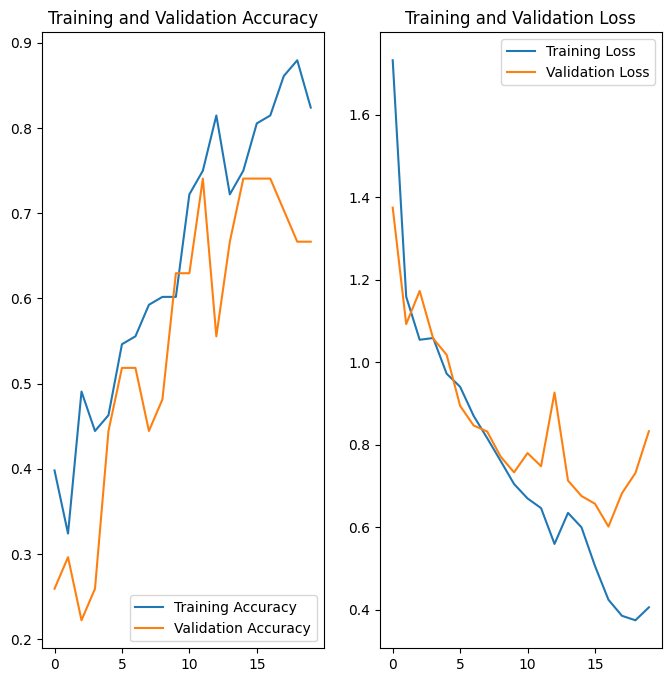

In [36]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [37]:
loss, accuracy = model.evaluate(train_ds)

4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 828ms/step - accuracy: 0.8426 - loss: 0.3799


In [38]:
loss, accuracy = model.evaluate(val_ds)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.6667 - loss: 0.8328


## confusion matrix

In [39]:
y_prediction = model.predict(test_dataset)
y_prediction = np.argmax (y_prediction, axis = 1)
y_prediction


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 807ms/step


array([0, 0, 0, 2, 2, 0, 2, 0, 2, 2, 1, 1, 0, 1, 0, 2, 2, 0, 0, 2])

In [40]:
#Create confusion matrix and normalizes it over predicted (columns)
result = confusion_matrix(numpy_labels, y_prediction , normalize='true')
print(result)

[[0.5 0.  0.5]
 [0.4 0.6 0. ]
 [0.4 0.  0.6]]


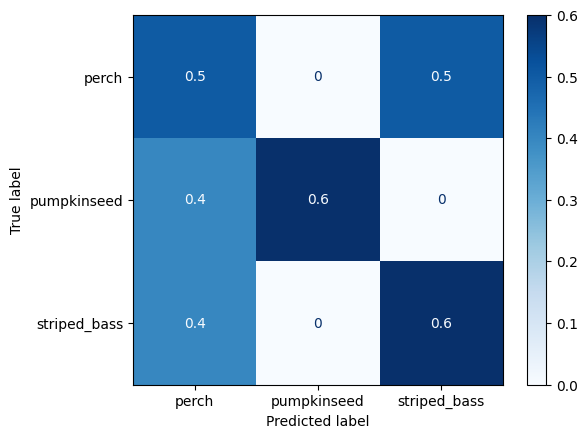

In [41]:
disp = ConfusionMatrixDisplay(confusion_matrix=result,
                              display_labels=class_names)
disp.plot(cmap='Blues')
plt.grid(False)

plt.show()